# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
    - To map the output to be as close as possible to the input by compressing the input, and then using a decoder to rebuild from it
2. What is the role of the bottleneck layer?  
    - Prevents the model from reconstructing the input perfectly
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
    - To equalize the size of your data your computing power (relates to reducing noise?)
    - dimensionality reduction, classification, denoising adn anomaly detection
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?
    - PCA is linear, while an autoencoder is nonlinear so can better separate nonlinear patterns between classes.


USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [1]:
from sklearn.datasets import fetch_openml
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset


mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

# per-image min-max (fixed transformation: uses only each image's own pixels)
X = torch.tensor(X, dtype=torch.float32)
X_min = X.min(dim=1, keepdim=True).values
X_max = X.max(dim=1, keepdim=True).values
X = (X - X_min) / (X_max - X_min)
y = torch.tensor(y, dtype=torch.long)

X_fit, _X, y_fit, _y = train_test_split(X, y, test_size=0.3, random_state=42)
X_tune, X_report, y_tune, y_report = train_test_split(_X, _y, test_size=0.5, random_state=42)

fitting_loader = DataLoader(TensorDataset(X_fit, y_fit), batch_size=128, shuffle=True)
tuning_loader = DataLoader(TensorDataset(X_tune, y_tune), batch_size=128, shuffle=False)
reporting_loader = DataLoader(TensorDataset(X_report, y_report), batch_size=128, shuffle=False)


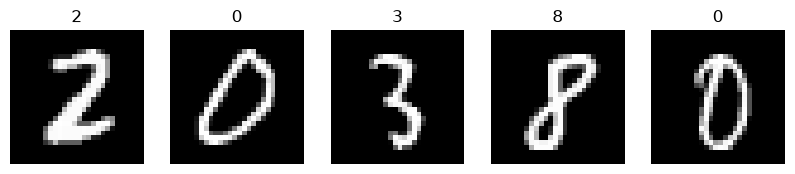

In [2]:
# visualize a few random digits
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i in range(5):
    idx = np.random.randint(0, X_fit.shape[0])
    axes[i].imshow(X_fit[idx].view(28, 28), cmap='gray')
    axes[i].set_title(str(y_fit[idx].item()))
    axes[i].axis('off')
plt.show()


## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [3]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            nn.Linear(784, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 2)  # bottleneck: linear only
        ]
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            nn.Linear(2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 784),
            nn.Sigmoid()  # output layer: no dropout
        ]
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output


### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

1. The sigmoid keeps outputs between [0,1], which is the same range as the normalized pixels. Using the same unit for both allows direct comparison with the input.

2. The task asks to reconstruct continuous pixel values in [0,1] as a regression problem, which indicates that MSE would be a good choice for the cost function. Squaring the errors penallizes large devitions between input and reconustrction, so the model is pushed to get the overall shape of each pixel

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [4]:
# TODO: Replace None to instantiate the autoencoder
model = Autoencoder()

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = nn.MSELoss()

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

In [5]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)
            cost = criterion(outputs, X_batch)
            cost.backward()
            optimizer.step()
            optimizer.zero_grad()
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [6]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.06419  Tuning Cost: 0.05053
Epoch [2/50]  Fitting Cost: 0.05090  Tuning Cost: 0.04856
Epoch [3/50]  Fitting Cost: 0.04956  Tuning Cost: 0.04740
Epoch [4/50]  Fitting Cost: 0.04895  Tuning Cost: 0.04658
Epoch [5/50]  Fitting Cost: 0.04858  Tuning Cost: 0.04606
Epoch [6/50]  Fitting Cost: 0.04829  Tuning Cost: 0.04585
Epoch [7/50]  Fitting Cost: 0.04811  Tuning Cost: 0.04570
Epoch [8/50]  Fitting Cost: 0.04793  Tuning Cost: 0.04542
Epoch [9/50]  Fitting Cost: 0.04772  Tuning Cost: 0.04531
Epoch [10/50]  Fitting Cost: 0.04762  Tuning Cost: 0.04502
Epoch [11/50]  Fitting Cost: 0.04746  Tuning Cost: 0.04488
Epoch [12/50]  Fitting Cost: 0.04737  Tuning Cost: 0.04485
Epoch [13/50]  Fitting Cost: 0.04731  Tuning Cost: 0.04465
Epoch [14/50]  Fitting Cost: 0.04715  Tuning Cost: 0.04439
Epoch [15/50]  Fitting Cost: 0.04710  Tuning Cost: 0.04438
Epoch [16/50]  Fitting Cost: 0.04699  Tuning Cost: 0.04437
Epoch [17/50]  Fitting Cost: 0.04702  Tuning Cost: 0.04421
Epoch 

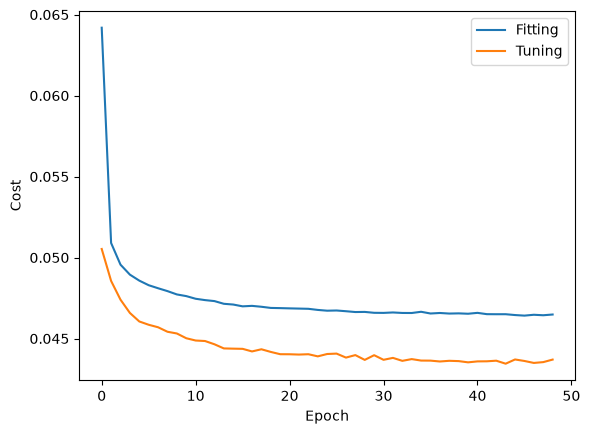

In [7]:
plt.plot(history["fitting"], label="Fitting")
plt.plot(history["tuning"], label="Tuning")
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.legend()
plt.show()


### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

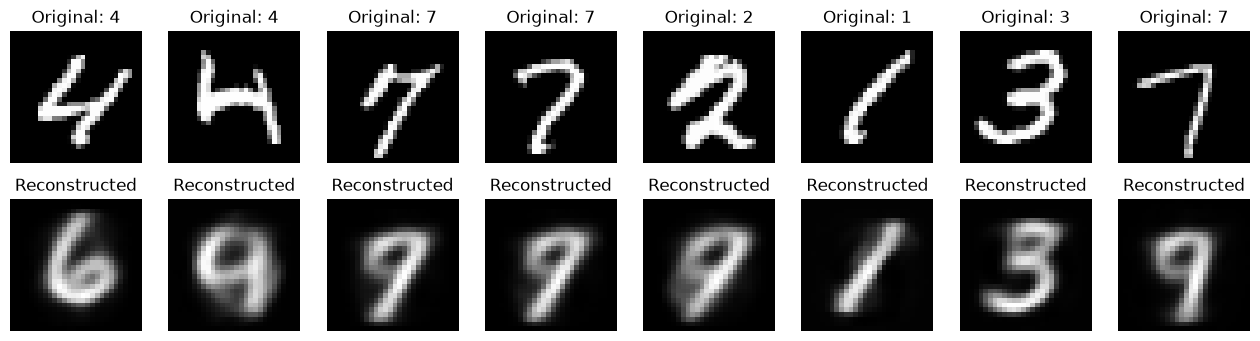

In [8]:
model.eval()
X_batch, y_batch = next(iter(reporting_loader))
with torch.no_grad():
    recon = model(X_batch)

n = 8
fig, axes = plt.subplots(2, n, figsize=(2 * n, 4))
for i in range(n):
    axes[0, i].imshow(X_batch[i].view(28, 28), cmap='gray')
    axes[0, i].set_title(f"Original: {y_batch[i].item()}")
    axes[1, i].imshow(recon[i].view(28, 28), cmap='gray')
    axes[1, i].set_title("Reconstructed")
    axes[0, i].axis('off')
    axes[1, i].axis('off')
plt.show()


The reconstructions are blurry but recognizable for most digits, however, some digits appear to be the complete wrong number. Similar-looking digits (e.g., 4/9, 3/5/8) are often confused, and even sometimes more distinct numbers like 4/6. In our sample, the 1 and 3 were reconstructed well, but every 7 and even a 2 came out as a 9, and the two 4s became a 9 and a 6. Overall, the reconstruction is only partly good: it captures the rough shape and position of the digit, but not reliably its identity.

The main reason is the 2-dimensional bottleneck. Squeezing 784 pixels into just 2 numbers keeps only the coarsest information, so the decoder outputs a blurry "average" digit for each region of the latent space instead of the specific handwriting. The latent plot (Section 4) supports this: digits like 0, 1, 2 and 6 get their own regions, while 4, 5, 7 and 9 are packed together in the center. Any input encoded there gets decoded as whatever digit dominates that area (here, a 9), which explains the 7→9 and 4→9 errors. MSE also makes the outputs blurry: when the model is unsure, averaging over possible strokes gives the lowest squared error. Finally, the training and tuning costs leveled off around 0.043–0.046 before early stopping, so more training probably wouldn't help; a larger bottleneck (e.g., 8–16 dimensions) would.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [9]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = X_batch
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [10]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

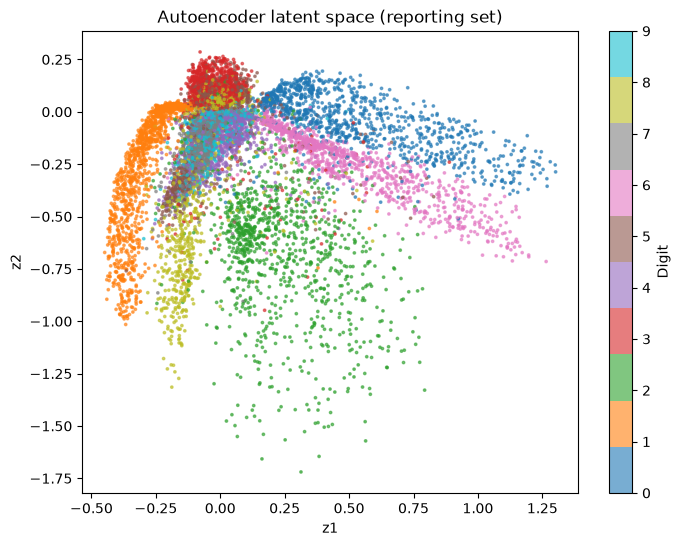

In [11]:
plt.figure(figsize=(8, 6))
sc = plt.scatter(latents_autoencoder[:, 0], latents_autoencoder[:, 1], c=labels, cmap='tab10', s=3, alpha=0.6)
plt.colorbar(sc, label="Digit")
plt.title("Autoencoder latent space (reporting set)")
plt.xlabel("z1")
plt.ylabel("z2")
plt.show()


## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

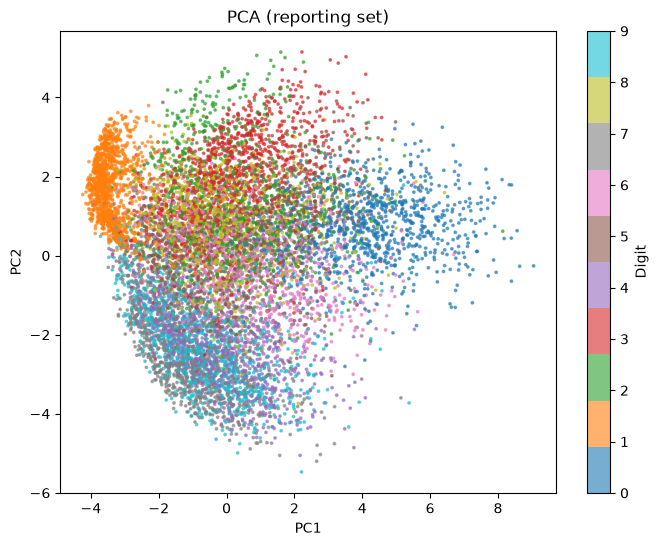

In [12]:
from sklearn.decomposition import PCA

# learn components on fitting + tuning data, transform reporting set
pca = PCA(n_components=2)
pca.fit(torch.cat([X_fit, X_tune]).numpy())
latents_pca = pca.transform(X_report.numpy())

plt.figure(figsize=(8, 6))
sc = plt.scatter(latents_pca[:, 0], latents_pca[:, 1], c=y_report.numpy(), cmap='tab10', s=3, alpha=0.6)
plt.colorbar(sc, label="Digit")
plt.title("PCA (reporting set)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


PCA is a linear projection, so most digit classes overlap heavily in one central cloud; only a few (e.g., 0 and 1) are partly separated along PC1. The autoencoder learns a nonlinear mapping, so its latent space shows more distinct clusters per digit (though similar digits like 4/7/9 still overlap). Its axes have no fixed meaning or ordering, unlike PCA components, which are orthogonal and ranked by explained variance.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE